# 🛡️ FraudLake — Jour 1 : Cadrage, HDFS distribué & Couche Bronze

> **Projet :** Détection de transactions bancaires frauduleuses sur une architecture *Data Lakehouse Médaillon*
> (HDFS 3 DataNodes · PySpark · Delta Lake · Streamlit)

| Bronze (J1) | Silver (J2) | Gold (J3) | Statistiques, ML & Dashboard (J4) |
|:---:|:---:|:---:|:---:|
| **▶ ingestion brute + lignage** | nettoyage, pseudonymisation, features | KPI & agrégats SQL | tests, segmentation, scoring |

### 🎯 Objectifs de la séance
1. **Cadrer le sujet métier** et sélectionner deux datasets Kaggle complémentaires reliés par une **clé de jointure temporelle**.
2. **Explorer le cluster HDFS réel** (`1 NameNode` + `3 DataNodes`, `dfs.blocksize = 16 Mo`, `dfs.replication = 2`).
3. **Téléverser les fichiers bruts** sur HDFS (`/lakehouse/bronze/raw/<source>/`) et observer leur découpage physique en blocs.
4. **Crash-test** : couper `datanode2`, observer la détection de panne (~50 s) et la ré-réplication automatique.
5. **Construire la couche Bronze** en Delta Lake avec traçabilité complète (`_source_dataset`, `_source_file`, `_ingested_at`, `_batch_id`).

---
## 📋 Fiche de cadrage du projet

| Rubrique | Contenu |
|---|---|
| **Titre du sujet** | **FraudLake** — Détection et analyse des transactions frauduleuses par carte bancaire |
| **Source principale (faits)** | [`kartik2112/fraud-detection`](https://www.kaggle.com/datasets/kartik2112/fraud-detection) — 1 852 394 transactions CB (jan. 2019 → déc. 2020), 999 porteurs, 693 commerçants, 14 catégories. 2 fichiers : `fraudTrain.csv` (335 Mo) + `fraudTest.csv` (143 Mo) |
| **Source complémentaire (enrichissement)** | [`donnetew/us-holiday-dates-2004-2021`](https://www.kaggle.com/datasets/donnetew/us-holiday-dates-2004-2021) — calendrier des 18 jours fériés / événements commerciaux US (Thanksgiving, Noël, Black-Friday eve…) |
| **Clé de jointure** | **Temporelle** : `DATE(trans_date_trans_time)` ⟷ `Date` (± fenêtre de 3 jours autour de chaque jour férié) |
| **Problématique métier** | *Quels signaux (montant, heure, canal, catégorie, vélocité, période festive) distinguent une transaction frauduleuse, et comment prioriser les alertes pour réduire les pertes sans saturer l'équipe anti-fraude ?* |
| **Variables temporelles** | `trans_date_trans_time`, `dob` (→ âge), jours fériés |
| **Variables quantitatives** | `amt` (montant, très asymétrique), `city_pop`, coordonnées porteur / commerçant (→ distance), vélocité 24 h |
| **Variables catégorielles / géographiques** | `category`, `merchant`, `gender`, `state`, `job` |
| **Cible** | `is_fraud` ∈ {0, 1} — classe rare (≈ 0,52 %) → déséquilibre extrême à gérer |

> 🔐 **Données personnelles.** Le dataset est **synthétique** (simulateur *Sparkov*) mais reproduit des champs sensibles
> (nom, adresse, n° de carte). Nous appliquons donc les réflexes RGPD d'un vrai projet bancaire :
> la couche **Bronze** reste un dépôt brut à accès restreint, la couche **Silver** est **pseudonymisée** dès le Jour 2.

## 1. Téléchargement des datasets Kaggle dans `/workspace/data_raw/<source>/`

Chaque dataset est isolé dans son propre sous-dossier (`data_raw/fraud-detection/`, `data_raw/us-holiday-dates-2004-2021/`)
afin d'éviter toute collision de noms. Le téléchargement est **idempotent** : il est ignoré si les fichiers sont déjà présents.

> 💡 Équivalent terminal : `task data:download DATASET="kartik2112/fraud-detection,donnetew/us-holiday-dates-2004-2021"`

In [1]:
import math
import re
import shutil
from pathlib import Path

import pandas as pd

DATA_RAW = Path("/workspace/data_raw")
DATA_RAW.mkdir(parents=True, exist_ok=True)
SUPPORTED_EXTS = {".csv", ".parquet", ".json", ".jsonl", ".tsv"}
MB = 1024 * 1024
HDFS_BLOCK = 16 * MB

KAGGLE_DATASETS: list[str] = [
    "kartik2112/fraud-detection",            # Source 1 — Faits : transactions CB étiquetées (train + test)
    "donnetew/us-holiday-dates-2004-2021",   # Source 2 — Enrichissement temporel : jours fériés US
]

for slug in KAGGLE_DATASETS:
    subdir = re.sub(r"[^a-zA-Z0-9._-]+", "_", slug.split("/")[-1]).strip("_") or "dataset"
    target_dir = DATA_RAW / subdir
    existing = [f for f in target_dir.rglob("*") if f.is_file() and f.suffix.lower() in SUPPORTED_EXTS] if target_dir.exists() else []
    if existing:
        print(f"✔ {slug:<40} déjà présent ({len(existing)} fichier(s)) — téléchargement ignoré")
        continue
    import kagglehub
    print(f"⬇ Téléchargement de {slug} -> {target_dir}/ ...")
    cache_dir = Path(kagglehub.dataset_download(slug))
    target_dir.mkdir(parents=True, exist_ok=True)
    for src_file in sorted(cache_dir.rglob("*")):
        if src_file.is_file() and src_file.suffix.lower() in SUPPORTED_EXTS:
            dest_file = target_dir / src_file.relative_to(cache_dir)
            dest_file.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(src_file, dest_file)

local_files = sorted(f for f in DATA_RAW.rglob("*") if f.is_file() and f.suffix.lower() in SUPPORTED_EXTS)
assert local_files, "Aucun fichier dans /workspace/data_raw/ : vérifiez `KAGGLE_DATASETS` ou lancez `task data:download`."

inventory = pd.DataFrame(
    {
        "source": f.relative_to(DATA_RAW).parts[0],
        "fichier": f.name,
        "taille_Mo": f.stat().st_size / MB,
        "blocs_HDFS_attendus": max(1, math.ceil(f.stat().st_size / HDFS_BLOCK)),
    }
    for f in local_files
)
total_mb = inventory["taille_Mo"].sum()
display(
    inventory.style.hide(axis="index")
    .format({"taille_Mo": "{:,.2f}"})
    .bar(subset=["taille_Mo"], color="#2a78d633")
    .set_caption(f"Inventaire local — {len(inventory)} fichiers, {total_mb:,.1f} Mo au total")
)

checks = {
    "Volumétrie cumulée entre 50 et 500 Mo": 50 <= total_mb <= 500,
    "Au moins un fichier > 32 Mo (découpage multi-blocs visible)": (inventory["taille_Mo"] > 32).any(),
    "Au moins 2 sources distinctes à joindre": inventory["source"].nunique() >= 2,
}
for label, ok in checks.items():
    print(("✅ " if ok else "❌ ") + label)

✔ kartik2112/fraud-detection               déjà présent (2 fichier(s)) — téléchargement ignoré
✔ donnetew/us-holiday-dates-2004-2021      déjà présent (1 fichier(s)) — téléchargement ignoré


source,fichier,taille_Mo,blocs_HDFS_attendus
fraud-detection,fraudTest.csv,143.39,9
fraud-detection,fraudTrain.csv,334.97,21
us-holiday-dates-2004-2021,US Holiday Dates (2004-2021).csv,0.01,1


✅ Volumétrie cumulée entre 50 et 500 Mo
✅ Au moins un fichier > 32 Mo (découpage multi-blocs visible)
✅ Au moins 2 sources distinctes à joindre


## 2. Démarrage de la `SparkSession` pré-configurée sur HDFS

Grâce à `config/spark-defaults.conf`, Spark pointe automatiquement vers `hdfs://namenode:9000` avec Delta Lake activé.
Nous fixons en plus le fuseau de session en **UTC** : les horodatages du dataset sont « naïfs » et un fuseau à heure d'été
(ex. `Europe/Paris`) ferait disparaître ou dupliquer certaines heures lors des passages été/hiver.

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # pandas 3 / PySpark : avertissement sans impact
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T

spark = (
    SparkSession.builder
    .appName("J1_HDFS_Ingestion_Bronze")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

default_fs = spark.conf.get("spark.hadoop.fs.defaultFS", "non défini")
block_size = spark.conf.get("spark.hadoop.dfs.blocksize", "non défini")
replication = spark.conf.get("spark.hadoop.dfs.replication", "non défini")

print(f"{'Spark version':<22}: {spark.version}")
print(f"{'Default FileSystem':<22}: {default_fs}")
print(f"{'HDFS Block Size':<22}: {block_size} octets" + (f" (= {int(block_size) // MB} Mo)" if block_size.isdigit() else ""))
print(f"{'HDFS Replication':<22}: {replication}")
print(f"{'Spark UI':<22}: http://localhost:4040")

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-a0688817-19e0-44e3-8b5e-d4c55d82222c;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.1 in central


	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central


	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found org.roaringbitmap#RoaringBitmap;0.9.25 in central
	found com.fasterxml.jackson.core#jackson-databind;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-annotations;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-core;2.13.5 in central
	found com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 in central
	found org.roaringbitmap#shims;0.9.25 in central
	found io.delta#delta-kernel-defaults;4.4.1 in central


	found org.apache.hadoop#hadoop-client-runtime;3.4.2 in central
	found org.apache.parquet#parquet-hadoop;1.16.0 in central
	found org.apache.parquet#parquet-column;1.16.0 in central
	found org.apache.parquet#parquet-common;1.16.0 in central
	found org.apache.parquet#parquet-format-structures;1.16.0 in central
	found javax.annotation#javax.annotation-api;1.3.2 in central
	found org.apache.parquet#parquet-encoding;1.16.0 in central


	found org.locationtech.jts#jts-core;1.20.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.7 in central
	found io.airlift#aircompressor;2.0.2 in central
	found commons-pool#commons-pool;1.6 in central
	found com.github.luben#zstd-jni;1.5.7-3 in central
	found org.apache.hadoop#hadoop-client-api;3.4.2 in central
	found commons-logging#commons-logging;1.3.0 in central
	found org.apache.parquet#parquet-jackson;1.16.0 in central
	found io.delta#delta-kernel-unitycatalog;4.4.1 in central
:: resolution report :: resolve 919ms :: artifacts dl 48ms
	:: modules in use:
	com.fasterxml.jackson.core#jackson-annotations;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-core;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-databind;2.13.5 from central in [default]
	com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 from central in [default]
	com.github.luben#zstd-jni;1.5.7-3 from central in [default]
	com.google.code.findbugs#jsr305;3.0.2 from 

	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   37  |   0   |   0   |   4   ||   33  |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spark#spark-submit-parent-a0688817-19e0-44e3-8b5e-d4c55d82222c
	confs: [default]
	0 artifacts copied, 33 already retrieved (0kB/48ms)


26/11/21 07:37:43 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark version         : 4.2.0
Default FileSystem    : hdfs://namenode:9000
HDFS Block Size       : 16777216 octets (= 16 Mo)
HDFS Replication      : 2
Spark UI              : http://localhost:4040


## 3. Téléversement sur HDFS & inspection des blocs de 16 Mo

La cellule suivante copie les fichiers de `/workspace/data_raw` vers `/lakehouse/bronze/raw/` en **normalisant les noms de
fichiers** (`US Holiday Dates (2004-2021).csv` → `us_holiday_dates_2004_2021.csv`, `fraudTrain.csv` → `fraud_train.csv`) :
espaces et parenthèses compliquent les chemins HDFS et les *globs* Spark. Le téléversement est **idempotent** (un fichier déjà
présent avec la même taille n'est pas recopié).

In [3]:
jvm = spark._jvm
hadoop_conf = spark._jsc.hadoopConfiguration()
fs = jvm.org.apache.hadoop.fs.FileSystem.get(hadoop_conf)
PathHDFS = jvm.org.apache.hadoop.fs.Path
RAW_HDFS = "/lakehouse/bronze/raw"


def hdfs_safe_name(file_name: str) -> str:
    """camelCase / espaces / parenthèses -> snake_case minuscule, extension conservée."""
    stem, suffix = Path(file_name).stem, Path(file_name).suffix.lower()
    stem = re.sub(r"(?<=[a-z0-9])(?=[A-Z])", "_", stem)
    stem = re.sub(r"[^A-Za-z0-9]+", "_", stem).strip("_").lower()
    return f"{stem}{suffix}"


fs.mkdirs(PathHDFS(RAW_HDFS))
uploaded = []
for file_path in local_files:
    rel = file_path.relative_to(DATA_RAW)
    dst = PathHDFS(f"{RAW_HDFS}/{'/'.join(rel.parts[:-1])}/{hdfs_safe_name(rel.name)}")
    size = file_path.stat().st_size
    if fs.exists(dst) and fs.getFileStatus(dst).getLen() == size:
        status = "déjà présent"
    else:
        fs.mkdirs(dst.getParent())
        fs.copyFromLocalFile(False, True, PathHDFS(f"file://{file_path}"), dst)
        status = "téléversé"
    uploaded.append({"fichier local": str(rel), "chemin HDFS": dst.toUri().getPath(), "statut": status})

display(pd.DataFrame(uploaded).style.hide(axis="index"))

fichier local,chemin HDFS,statut
fraud-detection/fraudTest.csv,/lakehouse/bronze/raw/fraud-detection/fraud_test.csv,téléversé
fraud-detection/fraudTrain.csv,/lakehouse/bronze/raw/fraud-detection/fraud_train.csv,téléversé
us-holiday-dates-2004-2021/US Holiday Dates (2004-2021).csv,/lakehouse/bronze/raw/us-holiday-dates-2004-2021/us_holiday_dates_2004_2021.csv,téléversé


In [4]:
# Inspection récursive : chaque bloc de 16 Mo et les DataNodes qui hébergent ses répliques
remote_iter = fs.listFiles(PathHDFS(RAW_HDFS), True)
statuses = []
while remote_iter.hasNext():
    statuses.append(remote_iter.next())
statuses.sort(key=lambda s: s.getLen(), reverse=True)
largest_hdfs_path = statuses[0].getPath().toUri().getPath()

block_rows = []
for status in statuses:
    rel_hdfs = status.getPath().toUri().getPath().split(f"{RAW_HDFS}/", 1)[-1]
    for idx, blk in enumerate(fs.getFileBlockLocations(status, 0, status.getLen())):
        for host in blk.getHosts():
            block_rows.append({
                "fichier": rel_hdfs, "bloc": idx, "taille_bloc_Mo": blk.getLength() / MB,
                "datanode": host, "réplication": status.getReplication(), "taille_fichier_Mo": status.getLen() / MB,
            })
blocks_pd = pd.DataFrame(block_rows)

summary = (
    blocks_pd.groupby("fichier")
    .agg(taille_Mo=("taille_fichier_Mo", "first"), blocs=("bloc", "nunique"),
         répliques=("datanode", "size"), facteur=("réplication", "first"))
    .assign(blocs_théoriques=lambda d: (d["taille_Mo"] / 16).apply(math.ceil).clip(lower=1))
    .sort_values("taille_Mo", ascending=False)
)
display(summary.style.format({"taille_Mo": "{:,.2f}"}).set_caption("Découpage physique des fichiers bruts sur HDFS"))
print(f"Fichier le plus volumineux : {largest_hdfs_path}")

# Détail des 4 premiers blocs du plus gros fichier (localisation des répliques)
largest_rel = largest_hdfs_path.split(f"{RAW_HDFS}/", 1)[-1]
display(
    blocks_pd[blocks_pd["fichier"] == largest_rel]
    .groupby("bloc").agg(taille_Mo=("taille_bloc_Mo", "first"), datanodes=("datanode", lambda h: ", ".join(sorted(h))))
    .head(4)
)

,taille_Mo,blocs,répliques,facteur,blocs_théoriques
fichier,,,,,
fraud-detection/fraud_train.csv,334.97,21,42,2,21
fraud-detection/fraud_test.csv,143.39,9,18,2,9
us-holiday-dates-2004-2021/us_holiday_dates_2004_2021.csv,0.01,1,2,2,1


Fichier le plus volumineux : /lakehouse/bronze/raw/fraud-detection/fraud_train.csv


,taille_Mo,datanodes
bloc,,
0,16.0,"datanode1, datanode2"
1,16.0,"datanode1, datanode2"
2,16.0,"datanode2, datanode3"
3,16.0,"datanode1, datanode3"


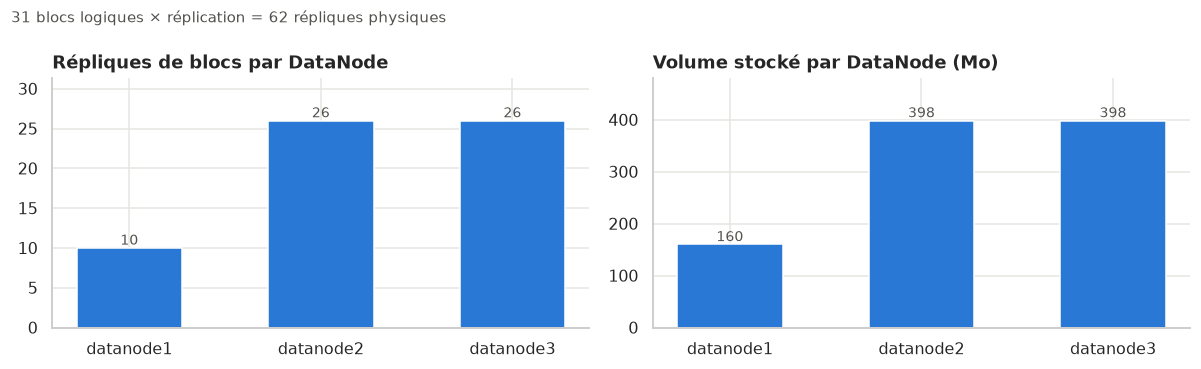

In [5]:
# --- Charte graphique commune aux notebooks FraudLake --------------------------
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)   # avertissements pandas 3 / PySpark sans impact

LEGIT, FRAUD, NEUTRAL = "#2a78d6", "#eb6834", "#9a9893"   # bleu = légitime, orange = fraude
CLASS_COLORS = {"Légitime": LEGIT, "Fraude": FRAUD}
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
    "grid.color": "#e6e5e1",
    "legend.frameon": False,
})


# Répartition des répliques de blocs par DataNode : HDFS équilibre-t-il bien le stockage ?
per_dn = blocks_pd.groupby("datanode").agg(répliques=("bloc", "size"), volume_Mo=("taille_bloc_Mo", "sum")).sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(per_dn.index, per_dn["répliques"], color=LEGIT, width=0.55)
axes[0].set_title("Répliques de blocs par DataNode")
axes[1].bar(per_dn.index, per_dn["volume_Mo"], color=LEGIT, width=0.55)
axes[1].set_title("Volume stocké par DataNode (Mo)")
for ax, col in zip(axes, ["répliques", "volume_Mo"]):
    for x, v in zip(per_dn.index, per_dn[col]):
        ax.text(x, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9, color="#52514e")
    ax.set_xlabel("")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
fig.suptitle(f"{blocks_pd['bloc'].groupby(blocks_pd['fichier']).nunique().sum()} blocs logiques × réplication "
             f"= {len(blocks_pd)} répliques physiques", x=0.01, ha="left", fontsize=10, color="#52514e")
plt.tight_layout()
fig.subplots_adjust(top=0.8)
plt.show()

### 🔎 Questions d'analyse (à confronter avec http://localhost:9870 → *Utilities › Browse the file system*)

**1. Nombre de blocs du plus gros fichier.** `fraud_train.csv` pèse **335,0 Mo** (351 238 196 octets) : 335,0 / 16 = 20,9 →
**21 blocs** (20 blocs pleins de 16 Mo + 1 bloc final de ≈ 14,9 Mo). `fraud_test.csv` (143,4 Mo) occupe **9 blocs**. L'interface
du NameNode affiche exactement ces valeurs (*Block information*).

**2. Un fichier de 3 Mo occupe-t-il 16 Mo ?** **Non.** La taille de bloc est un *maximum logique* : un bloc n'occupe sur le disque du
DataNode que la taille réelle de ses données. Notre calendrier de jours fériés (15 Ko) ne consomme donc que 15 Ko × 2 répliques.
En revanche, chaque fichier et chaque bloc coûtent **~150 octets de RAM au NameNode** : c'est la vraie raison du
*Small Files Problem* (traité au Jour 3 avec `OPTIMIZE`).

**3. Pourquoi `dfs.replication = 2` sur 3 DataNodes ?** Avec 2 répliques, la perte d'un nœud laisse toujours une copie lisible
**et** il reste un 3ᵉ nœud libre pour reconstruire la 2ᵉ réplique manquante. Avec `replication = 3`, il n'y aurait plus de nœud
cible après une panne : les blocs resteraient sous-répliqués. C'est aussi un compromis stockage : ×2 au lieu de ×3.

---
## 4. 💥 Crash-test : panne d'un DataNode et auto-réparation (~50 s)

Dans `config/hdfs-site.xml`, le délai de déclaration d'un DataNode mort a été abaissé de 10 min 30 s à :
$$2 \times \text{recheck-interval}\,(10\,s) + 10 \times \text{heartbeat.interval}\,(3\,s) = 50\,s$$

### Protocole (terminal)
1. État initial : `task hdfs:fsck` puis exécutez la cellule **« État du cluster »** ci-dessous.
2. Panne brutale : `task hdfs:crash-dn2` *(= `docker stop datanode2`)*.
3. Ré-exécutez la cellule « État du cluster » toutes les 15 s : `datanode2` passe **Dead** après ~50 s, le compteur de
   **blocs sous-répliqués** grimpe puis redescend à 0 quand le NameNode a recopié les blocs vers le DataNode survivant.
4. Pendant la panne, exécutez la lecture PySpark (exercice 4.1) : **aucune interruption de service**.
5. Restauration : `task hdfs:restore-dn2`.

In [6]:
import datetime as dt


def cluster_report() -> pd.DataFrame | None:
    """Vue client de l'état du cluster HDFS (équivalent allégé de `hdfs dfsadmin -report`)."""
    if fs.getClass().getSimpleName() != "DistributedFileSystem":
        print(f"ℹ️ Système de fichiers {fs.getClass().getSimpleName()} : rapport DataNodes disponible uniquement sur HDFS.")
        return None
    now_ms = jvm.java.lang.System.currentTimeMillis()
    rows = []
    for dn in fs.getDataNodeStats():
        silence_s = (now_ms - dn.getLastUpdate()) / 1000
        rows.append({
            "datanode": dn.getHostName(),
            "état": "🟢 Live" if silence_s < 30 else ("🟠 Stale" if silence_s < 50 else "🔴 Dead"),
            "dernier heartbeat (s)": round(silence_s, 1),
            "utilisé (Mo)": round(dn.getDfsUsed() / MB, 1),
            "libre (Go)": round(dn.getRemaining() / MB / 1024, 1),
        })
    under_replicated = None
    for getter in ("getLowRedundancyBlocksCount", "getUnderReplicatedBlocksCount"):
        try:
            under_replicated = getattr(fs, getter)()
            break
        except Exception:
            continue
    print(f"[{dt.datetime.now():%H:%M:%S}] Blocs sous-répliqués : {under_replicated}")
    return pd.DataFrame(rows).sort_values("datanode")


report = cluster_report()
if report is not None:
    display(report.style.hide(axis="index"))

[07:38:03] Blocs sous-répliqués : 0


datanode,état,dernier heartbeat (s),utilisé (Mo),libre (Go)
datanode1,🟢 Live,1.600000,161.300000,1.900000
datanode2,🟢 Live,1.500000,401.500000,1.900000
datanode3,🟢 Live,1.700000,401.500000,1.900000


### Exercice 4.1 — Continuité de service et *Data Locality*

Pendant que `datanode2` est arrêté, nous relisons le plus gros fichier. Point de rigueur souvent mal compris :
**le nombre de partitions Spark n'est pas directement le nombre de blocs HDFS**. Pour les sources fichiers, Spark calcule
une taille de découpe :

$$\text{split} = \min\Big(\texttt{maxPartitionBytes}\ (128\,\text{Mo}),\ \max\big(\texttt{openCostInBytes}\ (4\,\text{Mo}),\ \tfrac{\text{taille totale}}{\text{nb cœurs}}\big)\Big)$$

En abaissant `spark.sql.files.maxPartitionBytes` à 16 Mo, on **aligne 1 partition = 1 bloc HDFS** : chaque tâche lit alors
un bloc entier, idéalement sur le DataNode qui l'héberge (*Data Locality* `NODE_LOCAL`, visible dans l'onglet *Stages* de la Spark UI).

In [7]:
print("Fichier cible du test de résilience :", largest_hdfs_path)


def csv_reader():
    """Nouveau DataFrameReader à chaque appel : l'objet reader est mutable (.schema/.option le modifient en place)."""
    return spark.read.option("header", True).option("quote", '"').option("escape", '"')


df_check = csv_reader().csv(largest_hdfs_path)
n_rows = df_check.count()
p_default = df_check.rdd.getNumPartitions()

spark.conf.set("spark.sql.files.maxPartitionBytes", str(HDFS_BLOCK))
df_aligned = csv_reader().csv(largest_hdfs_path)
p_aligned = df_aligned.rdd.getNumPartitions()
spark.conf.unset("spark.sql.files.maxPartitionBytes")

n_blocks = summary.loc[largest_rel, "blocs"]
print(f"Nombre total de lignes lues                  : {n_rows:,}")
print(f"Cœurs disponibles (defaultParallelism)       : {spark.sparkContext.defaultParallelism}")
print(f"Partitions Spark (réglage par défaut)        : {p_default}")
print(f"Partitions Spark (maxPartitionBytes = 16 Mo) : {p_aligned}")
print(f"Blocs HDFS du fichier                        : {n_blocks}")
print("✅ 1 partition = 1 bloc HDFS" if p_aligned == n_blocks else "ℹ️ Écart dû au découpage à la frontière des lignes CSV")

Fichier cible du test de résilience : /lakehouse/bronze/raw/fraud-detection/fraud_train.csv


Nombre total de lignes lues                  : 1,296,675
Cœurs disponibles (defaultParallelism)       : 8
Partitions Spark (réglage par défaut)        : 8
Partitions Spark (maxPartitionBytes = 16 Mo) : 21
Blocs HDFS du fichier                        : 21
✅ 1 partition = 1 bloc HDFS


> **Lecture des résultats.** La lecture aboutit pendant la panne car chaque bloc possède une seconde réplique sur un DataNode
> vivant : le client HDFS bascule de façon transparente. Le nombre de lignes lues (**1 296 675**) est identique avant / pendant / après la panne.
>
> ⚠️ *N'oubliez pas* : `task hdfs:restore-dn2`. Au redémarrage, `datanode2` envoie un *block report* ; les répliques devenues
> excédentaires (3 au lieu de 2) sont supprimées automatiquement par le NameNode.

---
## 5. Construction de la couche Bronze en Delta Lake (`/lakehouse/bronze/`)

La couche Bronze conserve chaque source **fidèle à son contenu d'origine**, enrichie de colonnes de lignage :

| Colonne | Rôle |
|---|---|
| `_ingested_at` | horodatage d'ingestion (`current_timestamp()`) |
| `_source_dataset` | dataset Kaggle d'origine |
| `_source_file` | chemin HDFS exact du fichier (`_metadata.file_path`) — permet de distinguer *train* / *test* |
| `_batch_id` | identifiant unique du lot d'ingestion (rejeu / audit) |

**Choix d'ingénierie :**
- **Schéma explicite** pour les transactions (`StructType`) : pas de double lecture des 478 Mo pour `inferSchema`, typage
  déterministe et **`cc_num` / `zip` conservés en chaîne** (identifiants, pas des quantités : pas de perte de zéros ni d'arrondi).
- Les deux fichiers `fraud_train.csv` et `fraud_test.csv` partagent le même schéma : ils sont ingérés dans **une seule table
  Bronze** `transactions` en lisant le dossier source, l'origine restant traçable par `_source_file`.
- Les dates restent des chaînes en Bronze : leur typage (et la gestion des erreurs de parsing) est une règle métier du Silver.

In [8]:
import uuid

TRANSACTIONS_SCHEMA = T.StructType([
    T.StructField("row_id", T.LongType()),               # colonne d'index sans nom dans le CSV
    T.StructField("trans_date_trans_time", T.StringType()),
    T.StructField("cc_num", T.StringType()),
    T.StructField("merchant", T.StringType()),
    T.StructField("category", T.StringType()),
    T.StructField("amt", T.DoubleType()),
    T.StructField("first", T.StringType()),
    T.StructField("last", T.StringType()),
    T.StructField("gender", T.StringType()),
    T.StructField("street", T.StringType()),
    T.StructField("city", T.StringType()),
    T.StructField("state", T.StringType()),
    T.StructField("zip", T.StringType()),
    T.StructField("lat", T.DoubleType()),
    T.StructField("long", T.DoubleType()),
    T.StructField("city_pop", T.LongType()),
    T.StructField("job", T.StringType()),
    T.StructField("dob", T.StringType()),
    T.StructField("trans_num", T.StringType()),
    T.StructField("unix_time", T.LongType()),
    T.StructField("merch_lat", T.DoubleType()),
    T.StructField("merch_long", T.DoubleType()),
    T.StructField("is_fraud", T.IntegerType()),
])

#   "table_bronze": (dataset source, chemin brut HDFS, schéma explicite ou None pour inférence)
BRONZE_SOURCES: dict[str, tuple[str, str, T.StructType | None]] = {
    "transactions": ("kartik2112/fraud-detection", f"{RAW_HDFS}/fraud-detection/", TRANSACTIONS_SCHEMA),
    "us_holidays": ("donnetew/us-holiday-dates-2004-2021",
                    f"{RAW_HDFS}/us-holiday-dates-2004-2021/us_holiday_dates_2004_2021.csv", None),
}
assert len(BRONZE_SOURCES) >= 2, "Au moins 2 tables Bronze sont attendues pour la jointure du Jour 2."


def to_snake_case(name: str) -> str:
    name = re.sub(r"(?<=[a-z0-9])(?=[A-Z])", "_", name.strip())
    return re.sub(r"[^0-9a-zA-Z]+", "_", name).strip("_").lower()


batch_id = str(uuid.uuid4())
bronze_report = []
for table_name, (dataset_name, raw_path, schema) in BRONZE_SOURCES.items():
    bronze_delta_path = f"/lakehouse/bronze/{table_name}"
    reader = csv_reader().option("mode", "PERMISSIVE")
    reader = reader.schema(schema) if schema is not None else reader.option("inferSchema", True)
    df_raw = reader.csv(raw_path)
    df_raw = df_raw.toDF(*[to_snake_case(c) for c in df_raw.columns])

    (
        df_raw
        .withColumn("_ingested_at", F.current_timestamp())
        .withColumn("_source_dataset", F.lit(dataset_name))
        .withColumn("_source_file", F.col("_metadata.file_path"))
        .withColumn("_batch_id", F.lit(batch_id))
        .write.format("delta")
        .mode("overwrite")
        .option("overwriteSchema", "true")
        .save(bronze_delta_path)
    )

    df_bz = spark.read.format("delta").load(bronze_delta_path)
    cnt = df_bz.count()
    n_files = df_bz.select("_source_file").distinct().count()
    bronze_report.append({"table Bronze": bronze_delta_path, "source": dataset_name, "lignes": cnt,
                          "fichiers sources": n_files, "colonnes": len(df_bz.columns)})
    print(f"[BRONZE OK] {bronze_delta_path:<34} (source={dataset_name:<38}) -> {cnt:>10,} lignes")

display(pd.DataFrame(bronze_report).style.hide(axis="index").format({"lignes": "{:,}"}))

[BRONZE OK] /lakehouse/bronze/transactions     (source=kartik2112/fraud-detection            ) ->  1,852,394 lignes


[BRONZE OK] /lakehouse/bronze/us_holidays      (source=donnetew/us-holiday-dates-2004-2021   ) ->        342 lignes


table Bronze,source,lignes,fichiers sources,colonnes
/lakehouse/bronze/transactions,kartik2112/fraud-detection,"1,852,394",2,27
/lakehouse/bronze/us_holidays,donnetew/us-holiday-dates-2004-2021,342,1,10


In [9]:
# Aperçu Bronze : répartition par fichier source et taux de fraude brut (premier contact avec la cible)
(
    spark.read.format("delta").load("/lakehouse/bronze/transactions")
    .groupBy(F.regexp_extract("_source_file", r"([^/]+)$", 1).alias("fichier_source"))
    .agg(
        F.count("*").alias("transactions"),
        F.sum("is_fraud").alias("fraudes"),
        F.round(100 * F.avg("is_fraud"), 3).alias("taux_fraude_pct"),
        F.min("trans_date_trans_time").alias("première"),
        F.max("trans_date_trans_time").alias("dernière"),
    )
    .orderBy("première")
    .show(truncate=False)
)
spark.read.format("delta").load("/lakehouse/bronze/us_holidays").drop("_source_file", "_batch_id").show(5, truncate=False)

+---------------+------------+-------+---------------+-------------------+-------------------+
|fichier_source |transactions|fraudes|taux_fraude_pct|première           |dernière           |
+---------------+------------+-------+---------------+-------------------+-------------------+
|fraud_train.csv|1296675     |7506   |0.579          |2019-01-01 00:00:18|2020-06-21 12:13:37|
|fraud_test.csv |555719      |2145   |0.386          |2020-06-21 12:14:25|2020-12-31 23:59:34|
+---------------+------------+-------+---------------+-------------------+-------------------+



+----------+-----------+---------+-----+---+----+--------------------------+-----------------------------------+
|date      |holiday    |week_day |month|day|year|_ingested_at              |_source_dataset                    |
+----------+-----------+---------+-----+---+----+--------------------------+-----------------------------------+
|2004-07-04|4th of July|Sunday   |7    |4  |2004|2026-11-21 07:38:51.642154|donnetew/us-holiday-dates-2004-2021|
|2005-07-04|4th of July|Monday   |7    |4  |2005|2026-11-21 07:38:51.642154|donnetew/us-holiday-dates-2004-2021|
|2006-07-04|4th of July|Tuesday  |7    |4  |2006|2026-11-21 07:38:51.642154|donnetew/us-holiday-dates-2004-2021|
|2007-07-04|4th of July|Wednesday|7    |4  |2007|2026-11-21 07:38:51.642154|donnetew/us-holiday-dates-2004-2021|
|2008-07-04|4th of July|Friday   |7    |4  |2008|2026-11-21 07:38:51.642154|donnetew/us-holiday-dates-2004-2021|
+----------+-----------+---------+-----+---+----+--------------------------+--------------------

In [10]:
# ✅ Auto-contrôle de fin de Jour 1 : tables Delta valides dans /lakehouse/bronze/ + métadonnées physiques
bronze_root = PathHDFS("/lakehouse/bronze")
bronze_delta_tables = sorted(
    s.getPath().getName()
    for s in fs.listStatus(bronze_root)
    if s.isDirectory() and fs.exists(PathHDFS(s.getPath(), "_delta_log"))
)
assert {"transactions", "us_holidays"} <= set(bronze_delta_tables), f"Tables Bronze manquantes : {bronze_delta_tables}"

details = [
    spark.sql(f"DESCRIBE DETAIL delta.`/lakehouse/bronze/{t}`")
    .select(F.lit(t).alias("table"), "numFiles", (F.col("sizeInBytes") / MB).alias("taille_Mo"))
    .first().asDict()
    for t in bronze_delta_tables
]
display(pd.DataFrame(details).style.hide(axis="index").format({"taille_Mo": "{:,.1f}"})
        .set_caption("Tables Delta Bronze validées (Parquet compressé Snappy)"))

table,numFiles,taille_Mo
transactions,8,143.6
us_holidays,1,0.0


---
## 🧾 Bilan du Jour 1

- ✅ **2 sources Kaggle** (≈ 478 Mo) téléversées sur HDFS, découpées en **31 blocs** de 16 Mo répliqués ×2 sur 3 DataNodes.
- ✅ **Résilience démontrée** : lecture complète du fichier de 335 Mo pendant la panne de `datanode2`, ré-réplication automatique.
- ✅ **Couche Bronze Delta** : `transactions` (1 852 394 lignes) et `us_holidays` (342 lignes), avec lignage complet.
- 💾 Le format Delta/Parquet compressé divise l'empreinte disque par ≈ 3 par rapport au CSV brut.

➡️ **Jour 2** : diagnostic qualité, pseudonymisation RGPD, *feature engineering* anti-fraude et jointure avec le calendrier des jours fériés.